Algorithm described in Golay 1970.

In [2]:
import numpy as np
from itertools import combinations

import dLux as dl
import dLux.utils as dlu

import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm, CenteredNorm


In [3]:
# Hex axial neighbor directions
HEX_DIRECTIONS = [
    (1, 0), (0, 1), (-1, 1),
    (-1, 0), (0, -1), (1, -1)
]

def hex_neighbors(point):
    q, r = point
    return [(q + dq, r + dr) for dq, dr in HEX_DIRECTIONS]

def centroid(points):
    arr = np.array(points, dtype=float)
    return arr.mean(axis=0)

def distance(p, q):
    return np.linalg.norm(np.array(p) - np.array(q))

def pairwise_differences(points):
    diffs = []
    for p, q in combinations(points, 2):
        diff = ((p[0] - q[0])*10, (p[1] - q[1])*10)
        diffs.append(diff)
        diffs.append((-diff[0], -diff[1]))
    return diffs

def is_nonredundant(points):
    diffs = pairwise_differences(points)
    return len(diffs) == len(set(diffs))

def candidate_points(current_set, radius=5):
    """Generate candidate hex points within bounding radius."""
    qs = [p[0] for p in current_set]
    rs = [p[1] for p in current_set]
    
    qmin, qmax = min(qs)-radius, max(qs)+radius
    rmin, rmax = min(rs)-radius, max(rs)+radius
    
    candidates = []
    for q in range(qmin, qmax+1):
        for r in range(rmin, rmax+1):
            if (q, r) not in current_set:
                candidates.append((q, r))
    return candidates

def grow_hex_array(n_target):
    # Start with two neighboring points
    points = [(0, 0), (1, 0)]
    
    while len(points) < n_target:
        c = centroid(points)
        candidates = candidate_points(points)
        
        # Sort by distance to centroid
        candidates.sort(key=lambda p: distance(p, c))
        
        added = False
        for p in candidates:
            trial = points + [p]
            if is_nonredundant(trial):
                points.append(p)
                added = True
                break
        
        if not added:
            print("No valid candidate found.")
            break
    
    return points



In [20]:
nholes = 14
result = grow_hex_array(nholes)

In [21]:
r = 0.3
n_pix = 512 
prim_diam = nholes*1.5
pixel_coords = dlu.pixel_coords(n_pix, prim_diam)

sub_aps = []
for i, cen in enumerate(result):
    dl_tf = dl.CoordTransform(translation=cen)
    ap = dl.CircularAperture(radius=r, transformation=dl_tf)

    sub_aps.append(ap)

In [22]:
combined_ap = dl.MultiAperture(sub_aps)
trans=combined_ap.transmission(coords=pixel_coords, pixel_scale=prim_diam/n_pix)

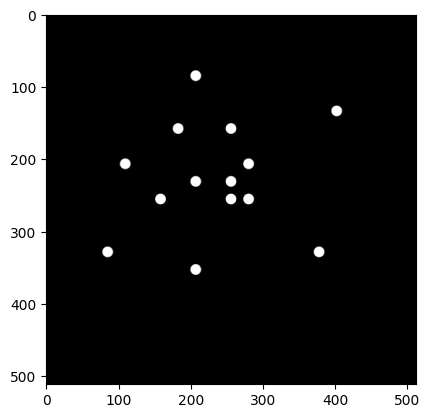

In [23]:
plt.imshow(trans, cmap='Greys_r')

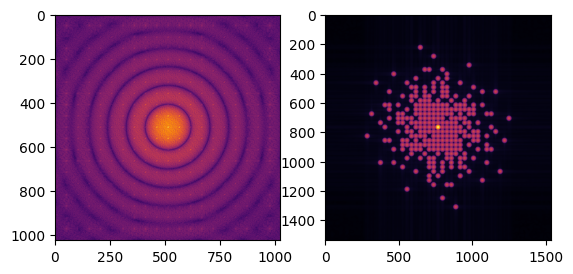

In [8]:
trans_padded=np.pad(trans, [(n_pix//2, n_pix//2), (n_pix//2, n_pix//2)], mode='constant')
psf = np.abs(np.fft.fftshift(np.fft.fft2(np.fft.fftshift(trans_padded))))**2
psf_padded = np.pad(psf, [(n_pix//2, n_pix//2), (n_pix//2, n_pix//2)], mode='constant')
OTF = np.abs(np.fft.fftshift(np.fft.fft2(np.fft.fftshift(psf_padded))))**2

plt.figure()
plt.subplot(1,2,1)
plt.imshow(psf, norm=PowerNorm(0.1), cmap='inferno')
plt.subplot(1,2,2)
plt.imshow(OTF, norm=PowerNorm(0.1), cmap='inferno')
plt.show()

In [13]:
import os
os.getcwd()    

'/Users/gpir9156/Documents/Git/phd-playground/FindNRArrayGolayAlg'

In [14]:
np.save(os.getcwd()+'/NRM-{}.npy'.format(nholes), result)

In [24]:
result

[(0, 0),
 (1, 0),
 (0, -1),
 (1, -2),
 (-2, -1),
 (0, -4),
 (-3, -4),
 (-4, 0),
 (-6, -2),
 (-2, -7),
 (-2, 4),
 (-7, 3),
 (5, 3),
 (6, -5)]